# 📱 SMS Spam Classifier

In this notebook you'll build a model that reads a text message and decides whether it's **spam** or **ham** (not spam).

Work through the cells from top to bottom. Each step has a **TODO** and a hint. Run a cell with **Shift + Enter**.

Stuck? `spam_classifier_SOLUTION.ipynb` has the answers — but try first!

## Setup
Import the libraries you'll need.

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split

DATA_PATH = "data/SMSSpamCollection"

## Step 1 — Load the data

In [2]:
df = pd.read_csv(DATA_PATH, sep="\t", header=None, names=["label", "text"], quoting=3)
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Step 2 — Explore

In [3]:
#print the shape and count of each label
df["label"].value_counts()
print("Shape" , df.shape)

Shape (5574, 2)


### Step 2b — Plot of label counts

<function matplotlib.pyplot.show(close=None, block=None)>

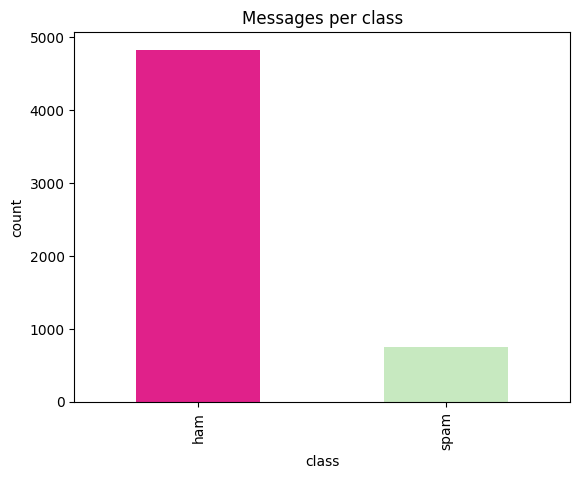

In [4]:
#bar chart of label counts (ham & spam)
df["label"].value_counts().plot(kind="bar", color=["#E0218A", "#C7E9C0"])
plt.title("Messages per class")
plt.xlabel("class")
plt.ylabel("count")
plt.show

## Step 3 — Clean the text

In [5]:
def clean_text(text):
    #lowercase the text
    text = text.lower()
    #replace anything that isn't a letter, number, or space
    text = re.sub("https\s+|www\.\s+", "url", text)
    text = re.sub(r"\d+", "num", text)
    text = re.sub(r"[^a-z0-9\s]" , " ", text)
    text = re.sub(r"\s+", " ", text)
    return text

# test it:
clean_text("WINNER!! Call 0906 1701 461 NOW to claim £1000")

'winner call num num num now to claim num'

Apply to every message

In [6]:
df["clean"] = df["text"].apply(clean_text)
df[["text", "clean"]].head()

,text,clean
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in num a wkly comp to win fa cup fi...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


## Step 4 — Split into train and test sets

**Your task:** convert labels to numbers (ham → 0, spam → 1), then split 80% train / 20% test.

*Hint:* `df["label"].map({...})` and `train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)`

🤔 **Look up:** what does `stratify=y` do, and why does it matter for imbalanced data?

In [7]:
#convert labels to numbers (ham -> 0, spam -> 1)
X = df["clean"]
y = df["label"].map({"ham":0, "spam":1})
#split 80% train/20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(len(X_train), len(X_test))

4459 1115


In [8]:
print("Train:", len(X_train), "| Test:", len(X_test))

# The spam ratio should be almost identical in both
print("Spam in train:", y_train.mean().round(3))
print("Spam in test: ", y_test.mean().round(3))

Train: 4459 | Test: 1115
Spam in train: 0.134
Spam in test:  0.134


## Step 5 — Turn text into numbers (TF-IDF)

In [9]:
vectorizer = TfidfVectorizer(ngram_range=(1,2), min_df=2)
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)
X_train_vec.shape

(4459, 11700)

In [10]:
# How big is the vocabulary?
print(len(vectorizer.vocabulary_))

# A few of the words/pairs it learned
print(vectorizer.get_feature_names_out()[1000:1020])

# The non-zero scores for the first training message
first = X_train_vec[0]
words = vectorizer.get_feature_names_out()
for idx, score in zip(first.indices, first.data):
    print(f"{words[idx]:20} {score:.3f}")
print("Original:", X_train.iloc[0])

11700
['biggest' 'biggest live' 'bill' 'billed' 'bills' 'bin' 'biola' 'bird'
 'birds' 'birla' 'birla soft' 'birth' 'birthdate' 'birthday'
 'birthday dear' 'birthday is' 'birthday may' 'birthday of'
 'birthday shijas' 'birthday wishes']
ok                   0.174
am                   0.183
on                   0.148
the                  0.117
way                  0.216
to                   0.095
home                 0.194
hi                   0.418
ok am                0.347
am on                0.303
on the               0.235
the way              0.257
way to               0.287
to home              0.329
hi hi                0.329
Original: ok i am on the way to home hi hi


## Step 6 — Train and compare two models

In [11]:
#Naive Bayes model
nb = MultinomialNB()
nb.fit(X_train_vec, y_train)
print("---- Naive Bayes ----")
print(classification_report(y_test, nb.predict(X_test_vec), target_names=("ham", "spam")))

#Logistic Regression model 
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_vec, y_train)
print("---- Logistic Regression ----")
print(classification_report(y_test, lr.predict(X_test_vec), target_names=("ham", "spam")))

---- Naive Bayes ----
              precision    recall  f1-score   support

         ham       0.97      1.00      0.99       966
        spam       1.00      0.81      0.90       149

    accuracy                           0.97      1115
   macro avg       0.99      0.91      0.94      1115
weighted avg       0.98      0.97      0.97      1115

---- Logistic Regression ----
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       966
        spam       0.98      0.88      0.93       149

    accuracy                           0.98      1115
   macro avg       0.98      0.94      0.96      1115
weighted avg       0.98      0.98      0.98      1115



## Step 7 — Confusion matrix

<function matplotlib.pyplot.show(close=None, block=None)>

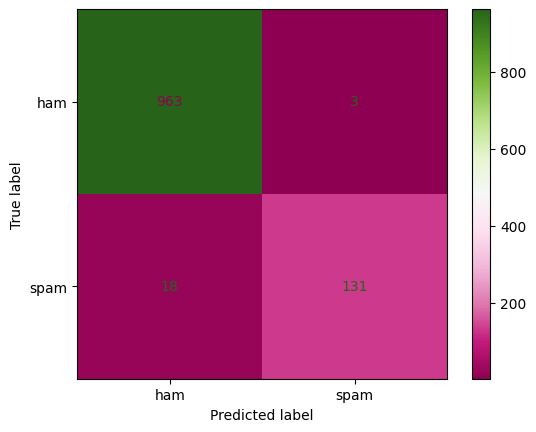

In [15]:
#plot a confusion matrix
best_model = lr  
ConfusionMatrixDisplay.from_estimator(best_model, X_test_vec, y_test, display_labels=["ham" , "spam"], cmap="PiYG")
plt.savefig("images/confusionmatrix.png", dpi=150, bbox_inches="tight")
plt.show

## Step 8 — Which words scream "spam"?

In [13]:
words = vectorizer.get_feature_names_out()
weights = lr.coef_[0]
top = pd.Series(weights, index=words).sort_values(ascending=False)
print("Top spam words:", list(top.index[:15]))
print("Top ham words: ", list(top.index[-15:]))

Top spam words: ['num', 'call num', 'to num', 'nump', 'free', 'call', 'txt', 'to', 'your', 'text', 'reply', 'www', 'uk', 'mobile', 'stop']
Top ham words:  ['then', 'll', 'got', 'in', 'da', 'but', 'it', 'at', 'lt gt', 'ok', 'that', 'gt', 'lt', 'me', 'my']


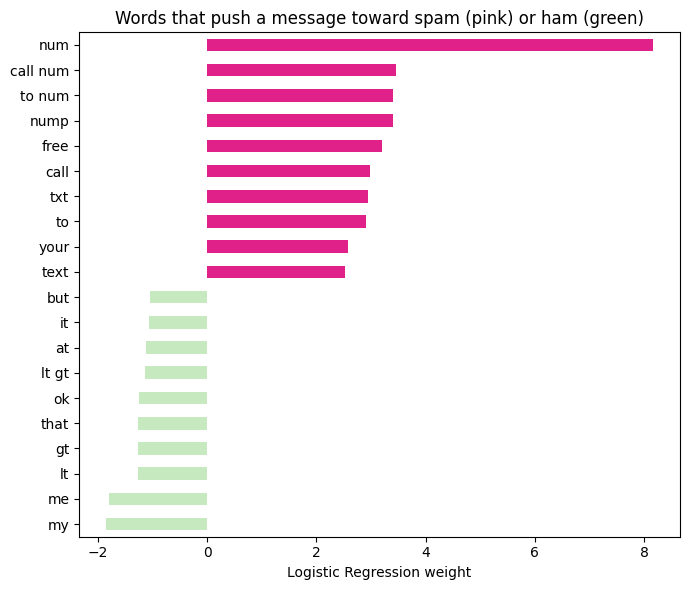

In [19]:
# Top 10 spam words + top 10 ham words, in one chart
show = pd.concat([top.head(10), top.tail(10)]).sort_values()
colors = ["#E0218A" if w > 0 else "#C7E9C0" for w in show]

show.plot(kind="barh", color=colors, figsize=(7, 6))
plt.title("Words that push a message toward spam (pink) or ham (green)")
plt.xlabel("Logistic Regression weight")
plt.tight_layout()
plt.savefig("images/top_words.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 9 — Try it on your own messages 🎉

Done for you. Change the messages and see what your model thinks!

In [14]:
def predict(message):
    vec = vectorizer.transform([clean_text(message)])
    spam_prob = best_model.predict_proba(vec)[0][1]
    return f"{'SPAM' if spam_prob >= 0.5 else 'ham'}  ({spam_prob:.1%} spam)"

for msg in [
    "Congratulations! You've won a free cruise. Reply YES to claim",
    "Hey, are we still on for lunch tomorrow?",
    "URGENT: your account has been suspended, click here",
    "Are you available tonight?",
    "Click the link to recieve a reward!",
]:
    print(predict(msg), "→", msg)

ham  (34.4% spam) → Congratulations! You've won a free cruise. Reply YES to claim
ham  (3.0% spam) → Hey, are we still on for lunch tomorrow?
ham  (12.9% spam) → URGENT: your account has been suspended, click here
ham  (2.9% spam) → Are you available tonight?
ham  (13.1% spam) → Click the link to recieve a reward!
